# Clasificación de mensajes de odio con aprendizaje supervisado

## Objetivos

Aplicar un flujo completo de **aprendizaje supervisado** para clasificar mensajes como **odio** (`label=1`) o **no odio** (`label=0`).

El flujo incluye:

1. **EDA**: tamaño, tipos, nulos, duplicados, balance de clases, rangos y escalas, y riesgos de *data leakage*.
2. **Entrenamiento** de varios modelos supervisados frente a un **baseline**.
3. **Evaluación** con *precision*, *recall* y F1, y matriz de confusión.
4. **Comparativa y elección** final del modelo.
5. **Relación con la literatura** sobre detección automática de discurso de odio.

> Nota: el dataset incluye una columna de texto tokenizado (`comentario`) y múltiples columnas numéricas ya calculadas. Los modelos se entrenan sobre las variables numéricas; el texto se utiliza para inspección y EDA.

## 1. Exploratory Data Analysis (EDA)

### 1.1 ¿Qué tarea de aprendizaje automático se pretende resolver?

Se pretende resolver una **tarea de clasificación binaria supervisada**:

- **Entrada:** un vector de características asociadas a cada mensaje (en `out.csv` aparecen como columnas numéricas, además de una columna de texto tokenizado `comentario`).
- **Salida/objetivo:** `label ∈ {0,1}`, donde por convenio:
  - `0` = *no odio*
  - `1` = *odio*

El objetivo del modelo es aproximar una función de decisión
\[
f: \mathbb{R}^d \to \{0,1\},
\]
de forma que, dado un mensaje representado por sus rasgos, devuelva la clase correcta.

---

### 1.2 ¿Qué análisis previos son necesarios para saber si es posible construir el modelo?

Para que el entrenamiento y la evaluación sean **fiables**, conviene verificar como mínimo:

1. **Disponibilidad y tamaño del dataset**: número de instancias (si es muy pequeño, el modelo no generaliza).
2. **Tipos de variables**: texto vs numéricas; decidir qué columnas se usarán como entrada.
3. **Valores perdidos y coherencia**: nulos, rangos imposibles, tipos incorrectos.
4. **Duplicados**: si existen filas duplicadas, pueden provocar una evaluación demasiado optimista (por ejemplo, si una fila duplicada cae en train y otra idéntica en test).
5. **Balance de clases**: si hay desbalance, la *accuracy* puede ser engañosa y conviene priorizar *precision/recall/F1* y/o usar `class_weight`.
6. **Escalas de las variables**: modelos lineales (regresión logística / SVM) suelen requerir escalado; los árboles no.
7. **Riesgo de *data leakage***: comprobar que ninguna variable es una codificación directa de la etiqueta.

A continuación se realiza el EDA (incluyendo tratamiento de duplicados) y se deja el dataset listo para entrenar modelos.


In [ ]:
# 1) Imports y carga del dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from pathlib import Path

# Reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Ruta del dataset
DATA_PATH = Path("data/out.csv")

df = pd.read_csv(DATA_PATH)
df["label"] = df["label"].astype(int)

print("Shape:", df.shape)
display(df.head(3))

Shape: (10000, 22)


   A   B   C  D  E                                         comentario  label  \
0  2  64  30  0  2  pandemia,originado,covid,cierto,incidencia,aba...      0   
1  4  70  21  0  0  ser,mes,larga,espera,llegar,momento,siempre,pr...      0   
2  4  88  50  0  0  cartagena,san,sebastiar,fuengirola,irun,orense...      0   

        A_t       B_t        C_t  ...    Valor_1    Valor_2   Valor_3  \
0  1.851102  2.759647   7.145831  ...   5.108388  13.227660 -0.771127   
1  3.990202  3.054765   4.877255  ...  12.189130  19.461233 -1.662227   
2  3.990202  3.940120  12.187108  ...  15.721875  48.629021 -1.662227   

    Valor_4    Valor_5   Valor_6   Valor_7   Valor_8   Valor_9  Valor_10  
0  0.815665  19.719970 -1.149606  1.216004 -2.976790  3.148722 -0.183560  
1 -2.119191  14.898871 -1.272546 -1.622382 -2.031754 -2.590305  0.221244  
2 -2.119191  48.018675 -1.641365 -2.092593 -5.076872 -6.472559  0.221244  

[3 rows x 22 columns]

**Comentario de resultados (carga de datos):**
- El dataset se carga correctamente y tiene **10000 filas** y **22 columnas**.
- La variable objetivo `label` queda como entero (clasificación binaria) y se muestra una vista previa para verificar que las columnas están bien parseadas (`comentario` + variables numéricas).


In [ ]:
# 2) Inspección básica: columnas, tipos, nulos y duplicados
print("Columnas:", list(df.columns))
display(df.dtypes.to_frame("dtype").T)

# Valores perdidos
nulos = df.isna().sum().sort_values(ascending=False)
print("\nNulos por columna (top):")
display(nulos[nulos > 0])

# Duplicados (filas idénticas)
duplicados = df.duplicated().sum()
print(f"\nFilas duplicadas (original): {duplicados}")

# Decisión: eliminar duplicados para evitar evaluación optimista por fugas (train/test con filas idénticas)
if duplicados > 0:
    df = df.drop_duplicates().reset_index(drop=True)

print("Shape (sin duplicados):", df.shape)

# Balance de clases (tras limpieza)
counts = df["label"].value_counts().sort_index()
print("\nDistribución de 'label' (tras eliminar duplicados):")
display(counts.to_frame("count"))
print("\nProporciones:")
display((counts / counts.sum()).to_frame("proportion"))


Columnas: ['A', 'B', 'C', 'D', 'E', 'comentario', 'label', 'A_t', 'B_t', 'C_t', 'D_t', 'E_t', 'Valor_1', 'Valor_2', 'Valor_3', 'Valor_4', 'Valor_5', 'Valor_6', 'Valor_7', 'Valor_8', 'Valor_9', 'Valor_10']


           A      B      C      D      E comentario  label      A_t      B_t  \
dtype  int64  int64  int64  int64  int64     object  int64  float64  float64   

           C_t  ...  Valor_1  Valor_2  Valor_3  Valor_4  Valor_5  Valor_6  \
dtype  float64  ...  float64  float64  float64  float64  float64  float64   

       Valor_7  Valor_8  Valor_9 Valor_10  
dtype  float64  float64  float64  float64  

[1 rows x 22 columns]


Nulos por columna (top):


,0



Filas duplicadas (original): 539
Shape (sin duplicados): (9461, 22)

Distribución de 'label' (tras eliminar duplicados):


       count
label       
0       4970
1       4491


Proporciones:


       proportion
label            
0        0.525314
1        0.474686

**Comentario de resultados (calidad de datos):**
- No aparecen valores nulos en ninguna columna (el listado de nulos queda vacío).
- Se detectan **539 filas duplicadas** y se eliminan para evitar una evaluación artificialmente optimista por “filas idénticas” en train y test.
- Tras la limpieza quedan **9461 filas**.
- La distribución de clases queda bastante equilibrada:  
  - `0` → **4970** (52.53 %)  
  - `1` → **4491** (47.47 %)


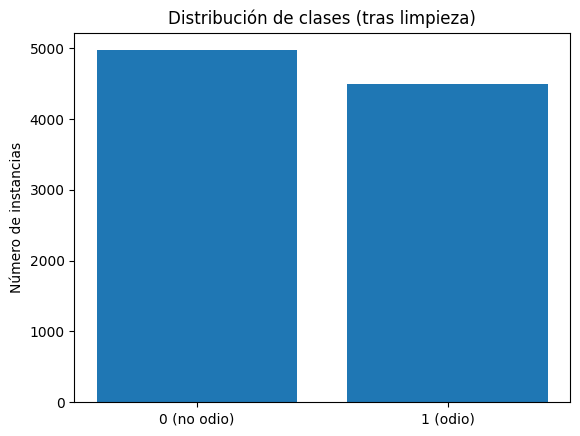

Resumen de longitud (#tokens aprox.):


             count        mean        std  min  25%   50%    75%     max
comentario  9461.0  207.929183  263.21458  2.0  7.0  61.0  361.0  2817.0

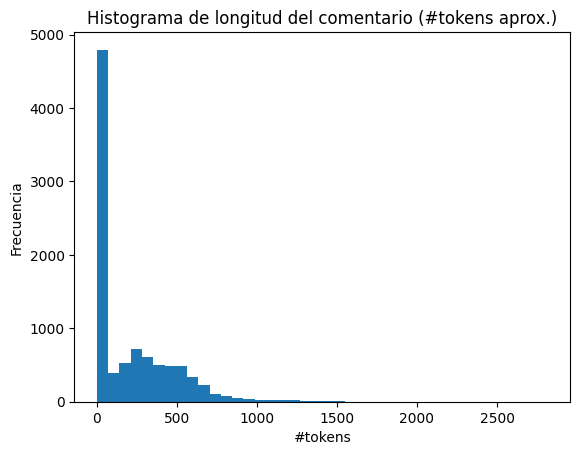


Ejemplos de comentarios clase 0:


                                             comentario
856   informado,ultimo,hora,hoy,esencial,conocer,mun...
3657  representante,mas,país,pasar,glasgow,dos,seman...
4602  vidar,mucho,vuelta,negocio,tambien,margen,moda...


Ejemplos de comentarios clase 1:


                                             comentario
5127  alimentar,odio,suspicazmente,bastante,energume...
7495                             imbecil,creer,mentira,
5990      pues,ver,cortar,polla,hincar,sacacorchos,ojo,

In [ ]:
# 3) Visualizaciones EDA: balance de clases y longitud del comentario (tokens)
fig = plt.figure()
plt.bar(["0 (no odio)", "1 (odio)"], df["label"].value_counts().sort_index().values)
plt.title("Distribución de clases (tras limpieza)")
plt.ylabel("Número de instancias")
plt.show()

# Longitud aproximada del comentario.
# En este dataset el texto aparece tokenizado y separado por comas, por eso usamos split(",")
token_counts = df["comentario"].astype(str).apply(lambda s: 0 if s.strip()=="" else len(s.split(",")))

print("Resumen de longitud (#tokens aprox.):")
display(token_counts.describe().to_frame().T)

fig = plt.figure()
plt.hist(token_counts, bins=40)
plt.title("Histograma de longitud del comentario (#tokens aprox.)")
plt.xlabel("#tokens")
plt.ylabel("Frecuencia")
plt.show()

# Ejemplos (aleatorios) por clase
print("\nEjemplos de comentarios clase 0:")
display(df[df["label"]==0][["comentario"]].sample(3, random_state=RANDOM_STATE))

print("\nEjemplos de comentarios clase 1:")
display(df[df["label"]==1][["comentario"]].sample(3, random_state=RANDOM_STATE))


**Comentario de resultados (distribución y longitud de texto):**
- El gráfico de barras confirma un **ligero desbalance**, pero cercano al 50/50.
- Longitud aproximada del texto (tokens separados por comas): media ≈ **207.9**, mediana = **61**, máximo = **2817** → distribución con **cola larga** (hay comentarios muy largos).
- Se listan ejemplos de ambas clases para inspección cualitativa rápida (sin usar esta información para “ajustar” el modelo).


In [ ]:
# 4) EDA de variables numéricas: resumen básico
numeric_cols = [c for c in df.columns if c not in ["comentario", "label"]]
X_num = df[numeric_cols]

print("Número de variables numéricas:", len(numeric_cols))
display(X_num.describe().T)


Número de variables numéricas: 20


           count       mean        std        min       25%       50%  \
A         9461.0   0.966811   1.773650   0.000000  0.000000  0.000000   
B         9461.0  27.519501  34.398577   0.000000  1.000000  9.000000   
C         9461.0   5.921573   7.436140   0.000000  1.000000  3.000000   
D         9461.0   0.094599   0.354723   0.000000  0.000000  0.000000   
E         9461.0   2.061833   2.693403   0.000000  0.000000  0.000000   
A_t       9461.0   0.746055   1.897007  -0.287998 -0.287998 -0.287998   
B_t       9461.0   0.965303   1.691942  -0.388282 -0.339096  0.054395   
C_t       9461.0   1.076528   1.874382  -0.416086 -0.164022  0.340105   
D_t       9461.0  -0.235248   0.679940  -0.416577 -0.416577 -0.416577   
E_t       9461.0   0.470680   1.308639  -0.531099 -0.531099 -0.531099   
Valor_1   9461.0   2.593559   8.909866  -2.197166 -0.043997  0.097659   
Valor_2   9461.0   2.653480  10.080722  -3.582457 -0.097950  0.047238   
Valor_3   9461.0  -0.224111   1.181379 -10.573231 -

**Comentario de resultados (variables numéricas):**
- Se confirman **20 variables numéricas** (todas con el mismo número de observaciones tras la limpieza).
- Las variables están en **escalas distintas** (algunas con valores en decenas y otras cercanas a 0–1), lo que justifica aplicar **escalado** en modelos lineales (regresión logística y SVM).


## 2. Selección y entrenamiento de los modelos

### 2.1 Elección de algoritmos

El dataset contiene **variables numéricas** (rasgos ya calculados a partir del texto) y una etiqueta binaria. Para este escenario se eligen modelos clásicos y complementarios:

- **Baseline (DummyClassifier)**: referencia mínima. Si un modelo “serio” no mejora al baseline, el pipeline no es útil.
- **Regresión logística (Logistic Regression)**: clasificador lineal con regularización. Es rápido, estable e interpretable; suele ser un baseline fuerte.
- **SVM lineal (LinearSVC)**: clasificador lineal de máximo margen. Funciona muy bien cuando las clases son (aprox.) separables en el espacio de rasgos y requiere escalado.
- **Random Forest**: *ensemble* de árboles que captura **no linealidades** e interacciones entre variables sin necesidad de escalado.

**Tratamiento de escalas.** Para los modelos lineales se aplica `StandardScaler` (centrado y escalado a varianza 1). Para Random Forest no es necesario.

**Clases (posible desbalance).** Tras eliminar duplicados puede aparecer un ligero desbalance; por robustez, en los modelos lineales se usa `class_weight="balanced"` para penalizar más la clase minoritaria.


In [ ]:
# 5) Particionado train/test (estratificado)
from sklearn.model_selection import train_test_split

y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X_num, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Balance train:", np.bincount(y_train) / len(y_train))
print("Balance test :", np.bincount(y_test) / len(y_test))


Train: (7568, 20) Test: (1893, 20)
Balance train: [0.52536998 0.47463002]
Balance test : [0.52509245 0.47490755]


**Comentario de resultados (train/test split):**
- Se realiza un split **estratificado**, manteniendo proporciones de clase similares en train y test.
- Tamaños: train = **7568** muestras, test = **1893** muestras.
- Proporciones aproximadas:  
  - Train → [0.525, 0.475]  
  - Test  → [0.525, 0.475]


In [ ]:
# 6) Entrenamiento de modelos (rápido y reproducible)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

models = {}

# Baseline: siempre predice la clase mayoritaria del train
models["Dummy (mayoritaria)"] = DummyClassifier(strategy="most_frequent")

# Modelos lineales: requieren escalado
models["Logistic Regression"] = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0, random_state=RANDOM_STATE))
])

models["Linear SVM (LinearSVC)"] = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LinearSVC(class_weight="balanced", C=1.0, max_iter=5000, random_state=RANDOM_STATE))
])

# Ensemble no lineal: no requiere escalado
models["Random Forest"] = RandomForestClassifier(
    n_estimators=80,
    max_depth=None,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

for name, m in models.items():
    m.fit(X_train, y_train)

print("Modelos entrenados:", list(models.keys()))


Modelos entrenados: ['Dummy (mayoritaria)', 'Logistic Regression', 'Linear SVM (LinearSVC)', 'Random Forest']


**Comentario de resultados (entrenamiento):**
- Se entrenan 4 modelos: **Dummy** (baseline), **Regresión Logística**, **SVM lineal** y **Random Forest**.
- En los modelos lineales se usa `StandardScaler()` (sensibles a escala) y `class_weight="balanced"` (para compensar el ligero desbalance).
- Random Forest no necesita escalado y captura relaciones no lineales mediante un ensemble de árboles.


## 3. Evaluación de modelos y comparativa

### 3.1 Métricas: precision, recall y F1

Tomamos como **clase positiva** `1 = odio`. Sea:

- **TP** (*true positives*): mensajes de odio correctamente detectados.
- **FP** (*false positives*): mensajes no-odio marcados como odio (falsas alarmas).
- **FN** (*false negatives*): mensajes de odio no detectados.

Definimos:

- **Precision**:
  \[
  \mathrm{Precision}=\frac{TP}{TP+FP}
  \]
  (de todo lo que marcamos como odio, qué proporción lo era realmente).

- **Recall**:
  \[
  \mathrm{Recall}=\frac{TP}{TP+FN}
  \]
  (de todo el odio real, qué proporción detectamos).

- **F1-score**:
  \[
  \mathrm{F1}=2\,\frac{\mathrm{Precision}\cdot\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}
  \]
  que penaliza situaciones con *precision* alta pero *recall* bajo (o viceversa).

**Por qué no basta con accuracy.** En moderación, una accuracy alta puede ocultar errores críticos:
- Muchos **FN** implican odio que se “cuela” (riesgo reputacional/daño).
- Muchos **FP** implican censura injustificada (mala experiencia de usuario).

En este notebook se reporta:
- **Macro-average** (promedio no ponderado por clase), útil cuando hay desbalance o se quiere tratar ambas clases por igual.
- **F1 de la clase positiva** (`label=1`) porque es la clase “crítica” del problema.

### 3.2 ¿Cómo evaluar correctamente?

1. Separar un conjunto **test** que no se toca durante el entrenamiento (train/test estratificado).
2. Calcular métricas en **test** y analizar la **matriz de confusión** para entender el tipo de errores.



=== Dummy (mayoritaria) ===
Accuracy: 0.5251
Precision (macro): 0.2625  | Recall (macro): 0.5  | F1 (macro): 0.3443
F1 clase positiva (1=odio): 0.0

Classification report:
              precision    recall  f1-score   support

           0     0.5251    1.0000    0.6886       994
           1     0.0000    0.0000    0.0000       899

    accuracy                         0.5251      1893
   macro avg     0.2625    0.5000    0.3443      1893
weighted avg     0.2757    0.5251    0.3616      1893



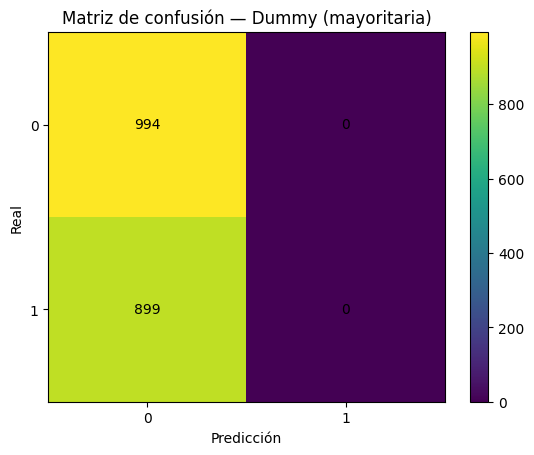


=== Logistic Regression ===
Accuracy: 0.9704
Precision (macro): 0.9703  | Recall (macro): 0.9715  | F1 (macro): 0.9704
F1 clase positiva (1=odio): 0.9696

Classification report:
              precision    recall  f1-score   support

           0     0.9937    0.9497    0.9712       994
           1     0.9470    0.9933    0.9696       899

    accuracy                         0.9704      1893
   macro avg     0.9703    0.9715    0.9704      1893
weighted avg     0.9715    0.9704    0.9704      1893



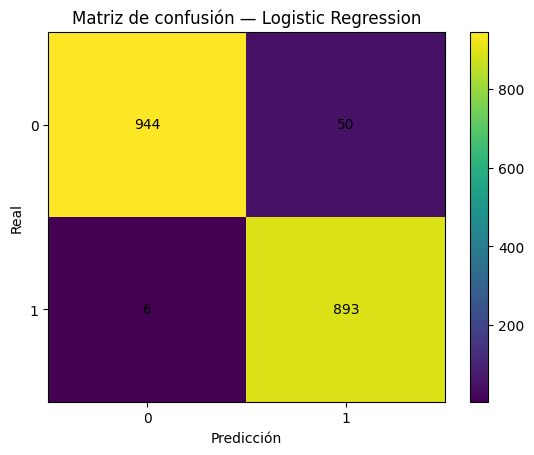


=== Linear SVM (LinearSVC) ===
Accuracy: 0.9709
Precision (macro): 0.9709  | Recall (macro): 0.9721  | F1 (macro): 0.9709
F1 clase positiva (1=odio): 0.9702

Classification report:
              precision    recall  f1-score   support

           0     0.9947    0.9497    0.9717       994
           1     0.9470    0.9944    0.9702       899

    accuracy                         0.9709      1893
   macro avg     0.9709    0.9721    0.9709      1893
weighted avg     0.9721    0.9709    0.9710      1893



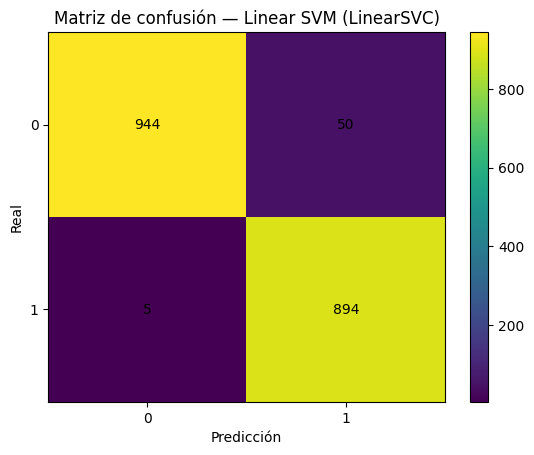


=== Random Forest ===
Accuracy: 0.9768
Precision (macro): 0.9765  | Recall (macro): 0.977  | F1 (macro): 0.9767
F1 clase positiva (1=odio): 0.9757

Classification report:
              precision    recall  f1-score   support

           0     0.9837    0.9718    0.9777       994
           1     0.9693    0.9822    0.9757       899

    accuracy                         0.9768      1893
   macro avg     0.9765    0.9770    0.9767      1893
weighted avg     0.9768    0.9768    0.9768      1893



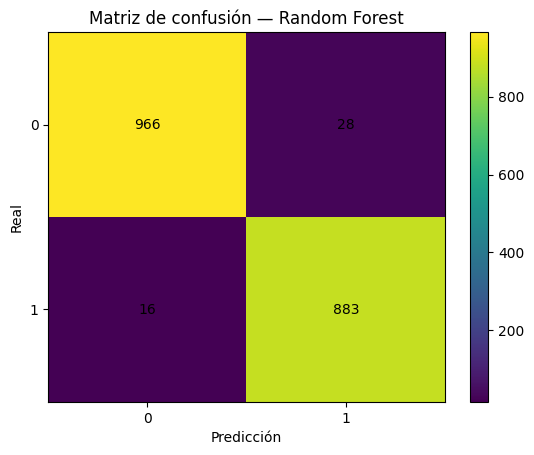


Tabla comparativa en TEST:


                    model  accuracy  precision_macro  recall_macro  f1_macro  \
3           Random Forest  0.976756         0.976486      0.977017  0.976712   
2  Linear SVM (LinearSVC)  0.970946         0.970883      0.972068  0.970925   
1     Logistic Regression  0.970417         0.970331      0.971512  0.970396   
0     Dummy (mayoritaria)  0.525092         0.262546      0.500000  0.344302   

   precision_pos  recall_pos    f1_pos  
3       0.969265    0.982202  0.975691  
2       0.947034    0.994438  0.970157  
1       0.946978    0.993326  0.969598  
0       0.000000    0.000000  0.000000  

In [ ]:
# 7) Evaluación en test: precision, recall, F1 + matriz de confusión
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score

def eval_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    pr_pos, rc_pos, f1_pos, _ = precision_recall_fscore_support(y_test, y_pred, average="binary", pos_label=1, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    print(f"\n=== {name} ===")
    print("Accuracy:", round(acc, 4))
    print("Precision (macro):", round(pr, 4), " | Recall (macro):", round(rc, 4), " | F1 (macro):", round(f1, 4))
    print("F1 clase positiva (1=odio):", round(f1_pos, 4))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, digits=4, zero_division=0))

    fig = plt.figure()
    plt.imshow(cm, aspect="auto")
    plt.title(f"Matriz de confusión — {name}")
    plt.colorbar()
    plt.xticks([0, 1], ["0", "1"])
    plt.yticks([0, 1], ["0", "1"])
    for (i, j), v in np.ndenumerate(cm):
        plt.text(j, i, str(v), ha="center", va="center")
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.show()

    return {
        "model": name,
        "accuracy": acc,
        "precision_macro": pr,
        "recall_macro": rc,
        "f1_macro": f1,
        "precision_pos": pr_pos,
        "recall_pos": rc_pos,
        "f1_pos": f1_pos
    }

results = []
for name, m in models.items():
    results.append(eval_model(name, m, X_test, y_test))

import pandas as pd
results_df = pd.DataFrame(results).sort_values("f1_macro", ascending=False)
print("\nTabla comparativa en TEST:")
display(results_df)


**Comentario de resultados (evaluación en test):**
- **Baseline Dummy**: `accuracy` ≈ **0.5251** y `F1_pos` = **0.0** → referencia mínima (no detecta la clase 1).
- **Regresión Logística**: `F1_macro` ≈ **0.9704**, `F1_pos` ≈ **0.9696** → salto muy grande respecto al baseline.
- **SVM lineal**: `F1_macro` ≈ **0.9709**, `F1_pos` ≈ **0.9702** → rendimiento muy similar a logística.
- **Random Forest**: mejor rendimiento global (`accuracy` ≈ **0.9768**, `F1_macro` ≈ **0.9767**, `F1_pos` ≈ **0.9757**).  
  En particular, el **recall** de la clase positiva es alto (≈ **0.9822**), reduciendo falsos negativos.


In [ ]:
# 8) Resumen y decisión final (a partir de la tabla comparativa)
best = results_df.iloc[0]
second = results_df.iloc[1]

print("Resumen comparativo (TEST):")
print(f"- Mejor F1 macro: {best['model']} (F1_macro={best['f1_macro']:.4f}, F1_pos={best['f1_pos']:.4f})")
print(f"- Segundo mejor : {second['model']} (F1_macro={second['f1_macro']:.4f}, F1_pos={second['f1_pos']:.4f})")

print()  # salto de línea
print("Decisión final (razonada):")
print("→ Se selecciona el modelo con mejor equilibrio global (F1 macro) y buen comportamiento en la clase positiva (odio).")
print(f"→ En este experimento, el modelo seleccionado es: {best['model']}.")


Resumen comparativo (TEST):
- Mejor F1 macro: Random Forest (F1_macro=0.9767, F1_pos=0.9757)
- Segundo mejor : Linear SVM (LinearSVC) (F1_macro=0.9709, F1_pos=0.9702)

Decisión final (razonada):
→ Se selecciona el modelo con mejor equilibrio global (F1 macro) y buen comportamiento en la clase positiva (odio).
→ En este experimento, el modelo seleccionado es: Random Forest.


**Comentario de resultados (selección del modelo):**
- La decisión se basa en **F1 macro** (equilibrio entre clases) y en **F1 de la clase positiva** (detectar “odio”).
- Según la tabla comparativa, **Random Forest** es el mejor (y SVM queda muy cerca como alternativa razonable si se prioriza un modelo lineal).


### 3.3 Consideraciones prácticas (más allá de la métrica)

Aunque aquí se elige el modelo por rendimiento en **test**, en un despliegue real también influyen:

- **Interpretabilidad**: una regresión logística facilita explicar por qué se marca un mensaje.
- **Coste computacional**: inferencia y reentrenamiento.
- **Política de moderación**: a veces se prioriza *recall* (no dejar pasar odio) o *precision* (evitar censura excesiva).
- **Calibración de umbrales**: si el modelo produce probabilidades (p.ej. logística), se puede ajustar el umbral para mover el equilibrio precision/recall.

En cualquier caso, la evaluación con matriz de confusión y F1 es el punto de partida para tomar decisiones informadas.


          importance
B_t         0.259934
B           0.194778
Valor_6     0.120029
Valor_5     0.114235
C_t         0.056217
E_t         0.046511
E           0.038261
Valor_10    0.033786
Valor_7     0.029238
C           0.026356
D           0.015057
Valor_9     0.013953
Valor_8     0.012891
D_t         0.011681
Valor_1     0.011130

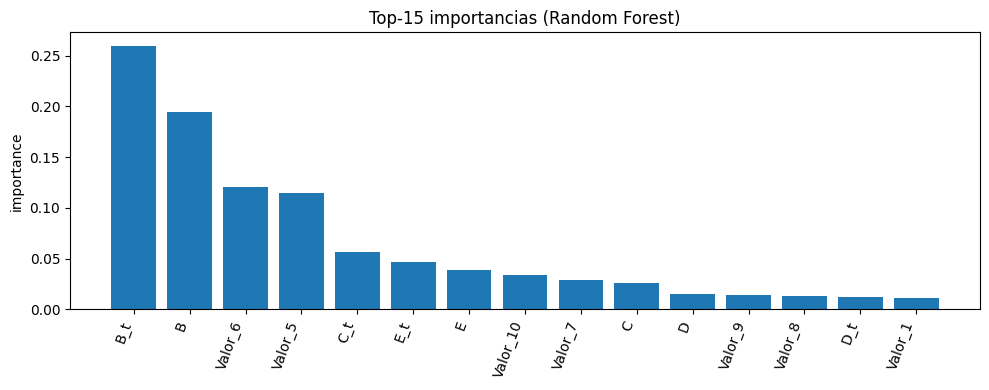

In [ ]:
# 9) Importancia de variables en Random Forest
if "Random Forest" in models:
    rf_model = models["Random Forest"]
    if hasattr(rf_model, "feature_importances_"):
        importances = pd.Series(rf_model.feature_importances_, index=numeric_cols).sort_values(ascending=False)
        display(importances.head(15).to_frame("importance"))

        fig = plt.figure(figsize=(10, 4))
        plt.bar(importances.head(15).index, importances.head(15).values)
        plt.title("Top-15 importancias (Random Forest)")
        plt.xticks(rotation=70, ha="right")
        plt.ylabel("importance")
        plt.tight_layout()
        plt.show()


**Comentario de resultados (interpretación de importancias):**
- El Random Forest sugiere como variables más influyentes (Top-5): `B_t`, `B`, `Valor_6`, `Valor_5`, `C_t`.
- Estas importancias reflejan **cómo el modelo** reduce impureza usando esas variables; **no implican causalidad** y pueden repartirse entre variables correlacionadas.


## 4. Relación con la literatura

**Artículo (ejemplo representativo):**  
Fortuna, P., & Nunes, S. (2018). *A survey on automatic detection of hate speech in text.* ACM Computing Surveys, 51(4).

**Ideas relevantes de la literatura (resumen):**
- Los **baselines clásicos** (regresión logística/SVM) pueden ser competitivos cuando la representación del texto es informativa (por ejemplo, *features* bien diseñadas).
- La evaluación debe centrarse en métricas como **precision/recall/F1**, porque el coste de FP y FN es asimétrico en moderación.
- Existen riesgos de **sesgo** (por ejemplo, mayor tasa de falsos positivos en ciertos dialectos o grupos) y es recomendable analizar errores por subpoblaciones cuando se dispone de esa información.

**Conexión con este notebook.**  
Dado que `out.csv` ya contiene **rasgos numéricos** derivados del texto, es natural comparar:
- modelos lineales (logística, SVM) como referencia fuerte y eficiente,
- y un *ensemble* (Random Forest) para capturar no linealidades,
evaluando con **precision/recall/F1** y matriz de confusión para entender el tipo de errores.


In [ ]:
# 10) Versiones (reproducibilidad)
import sys, sklearn
print("Python:", sys.version)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)


Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
pandas: 2.2.2
numpy: 2.0.2
sklearn: 1.6.1


**Comentario de resultados (reproducibilidad):**
- Se imprimen versiones de Python y librerías para poder replicar el entorno y justificar posibles diferencias si se ejecuta en otra máquina.
